C:\Users\n\AppData\Local\Temp\ipykernel_668\2596025338.py:23: Pandas4Warning: The default value of 'encoding' in read_sas is deprecated. In a future version the default will change from None to 'infer', and character columns will be decoded rather than returned as bytes (XPORT files record no encoding, so 'infer' means 'ISO-8859-1'). Pass encoding='infer' to adopt the future behavior, or encoding=None to keep the current one.
  paq = pd.read_sas('../data/PAQ_L.xpt')


حجم نمونه تحلیلی در فاز دوم (N): 5420

--- ۱. احتمال‌های حاشیه‌ای، مشترک و شرطی ---
احتمال حاشیه‌ای افسردگی P(A):                     0.1328
احتمال حاشیه‌ای کم‌تحرکی شدید P(B):               0.3386
احتمال مشترک وقوع هم‌زمان P(A ∩ B):             0.0531
حاصل‌ضرب احتمال‌های حاشیه‌ای P(A) * P(B):         0.0450
احتمال شرطی افسردگی به شرط کم‌تحرکی P(A | B):     0.1569
احتمال شرطی افسردگی به شرط تحرک مناسب P(A | B'): 0.1205
احتمال افسردگی در مردان P(A | Male):              0.1060
احتمال افسردگی در زنان P(A | Female):             0.1554

--- ۲. محاسبه بیزی ---
احتمال کم‌تحرکی شدید به شرط داشتن افسردگی P(B | A): 0.4000

--- ۳. مقایسه احتمال تجربی خام و وزن‌دار ---
احتمال خام افسردگی در نمونه:       0.1328 (13.28%)
احتمال وزن‌دار افسردگی در جامعه:   0.1281 (12.81%)

--- ۴. مقایسه توزیع تجربی شمارش با مدل دوجمله‌ای (n=20) ---
 تعداد_افراد_افسرده(k)  احتمال_تجربی  احتمال_نظری_دوجمله‌ای
                     0      0.062731               0.057806
                     1      0.158672               

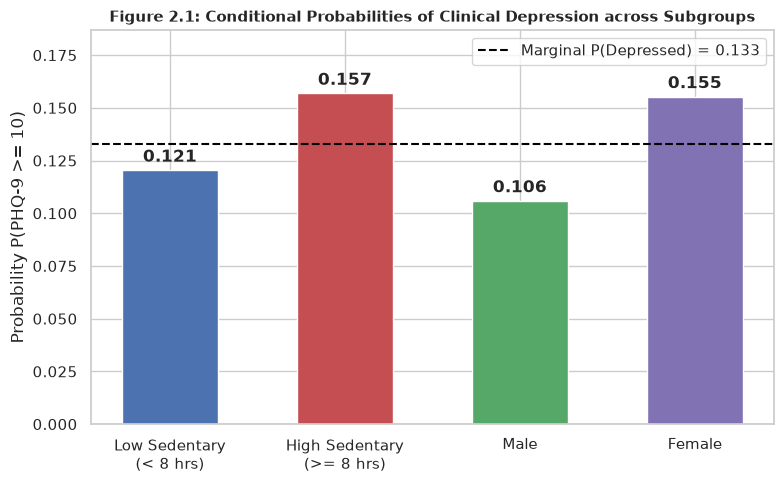

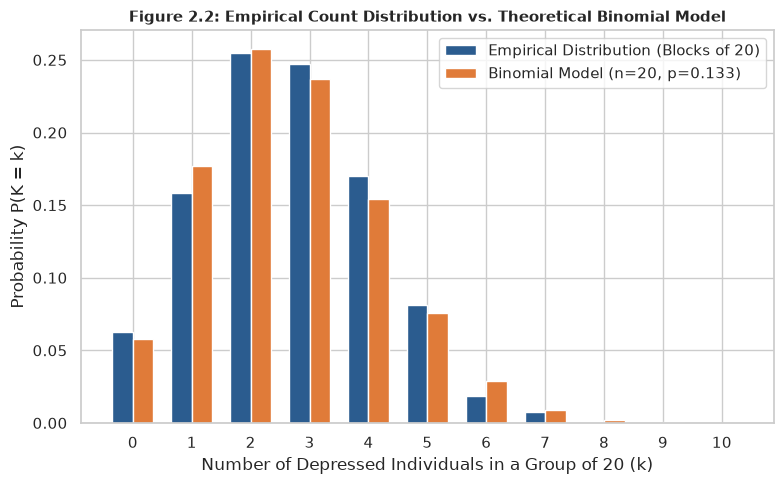

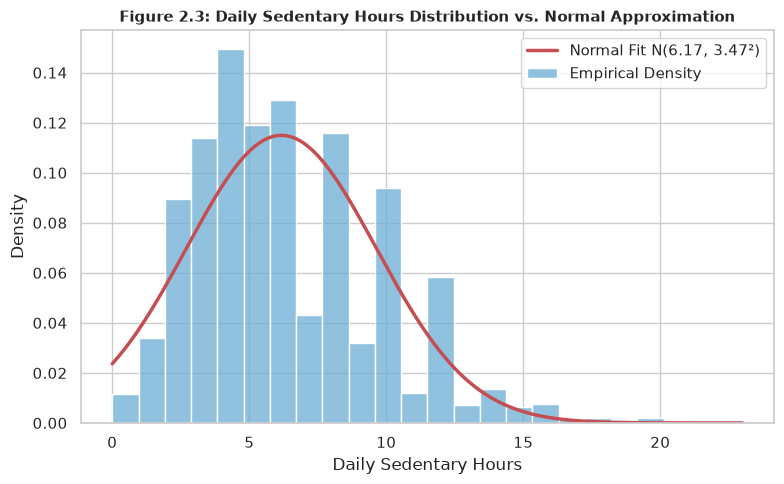

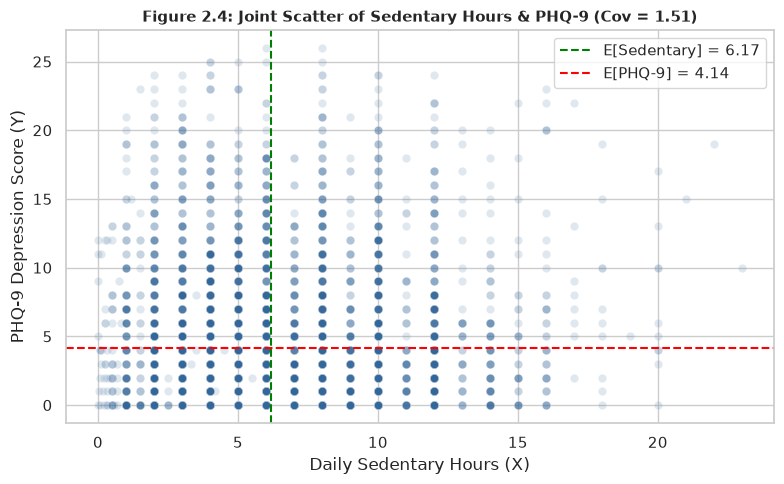


کلیه محاسبات و نمودارهای فاز دوم با موفقیت اجرا و در پوشه figures ذخیره شدند.


In [2]:
# ==============================================================================
# پروژه درس آمار - فاز دوم: احتمال و توزیع‌های احتمالی
# مسیر الف: NHANES 2021-2023 | کم‌تحرکی روزانه و سلامت روان (PHQ-9)
# ==============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os

sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False
os.makedirs('../figures', exist_ok=True)

# ------------------------------------------------------------------------------
# ۰. بارگذاری و آماده‌سازی جمعیت تحلیلی (مشابه فاز اول)
# ------------------------------------------------------------------------------
demo = pd.read_sas('../data/DEMO_L.xpt')
dpq = pd.read_sas('../data/DPQ_L.xpt')
paq = pd.read_sas('../data/PAQ_L.xpt')

for df_temp in [demo, dpq, paq]:
    df_temp.columns = df_temp.columns.str.upper()

df = demo.merge(dpq, on='SEQN', how='inner').merge(paq, on='SEQN', how='inner')

dpq_cols = [f'DPQ0{i}0' for i in range(1, 10)]
for col in dpq_cols:
    df.loc[df[col].isin([7, 9]), col] = np.nan

df['phq9_score'] = df[dpq_cols].sum(axis=1, skipna=False)
df['age'] = df['RIDAGEYR']
df['gender'] = df['RIAGENDR'].map({1.0: 'Male', 2.0: 'Female'})
df['weight'] = df['WTINT2YR']

df.loc[df['PAD680'].isin([7777, 9999]), 'PAD680'] = np.nan
df['sedentary_hours'] = df['PAD680'] / 60.0

analytic_df = df[(df['age'] >= 18) & (df['phq9_score'].notna()) & (df['sedentary_hours'].notna())].copy()
N = len(analytic_df)
print(f"حجم نمونه تحلیلی در فاز دوم (N): {N}\n")

# ------------------------------------------------------------------------------
# ۱. تعریف رویدادها و متغیرهای تصادفی (تسک ۱)
# ------------------------------------------------------------------------------
analytic_df['Event_A_Depressed'] = (analytic_df['phq9_score'] >= 10).astype(int)
analytic_df['Event_B_HighSedentary'] = (analytic_df['sedentary_hours'] >= 8).astype(int)

# ------------------------------------------------------------------------------
# ۲. احتمال‌های حاشیه‌ای، مشترک، شرطی و بررسی استقلال (تسک ۲، ۳ و ۴ و الزام الف ۱)
# ------------------------------------------------------------------------------
p_A = analytic_df['Event_A_Depressed'].mean()
p_B = analytic_df['Event_B_HighSedentary'].mean()
p_A_and_B = ((analytic_df['Event_A_Depressed'] == 1) & (analytic_df['Event_B_HighSedentary'] == 1)).mean()

p_A_given_B = analytic_df[analytic_df['Event_B_HighSedentary'] == 1]['Event_A_Depressed'].mean()
p_A_given_not_B = analytic_df[analytic_df['Event_B_HighSedentary'] == 0]['Event_A_Depressed'].mean()

p_A_male = analytic_df[analytic_df['gender'] == 'Male']['Event_A_Depressed'].mean()
p_A_female = analytic_df[analytic_df['gender'] == 'Female']['Event_A_Depressed'].mean()

print("--- ۱. احتمال‌های حاشیه‌ای، مشترک و شرطی ---")
print(f"احتمال حاشیه‌ای افسردگی P(A):                     {p_A:.4f}")
print(f"احتمال حاشیه‌ای کم‌تحرکی شدید P(B):               {p_B:.4f}")
print(f"احتمال مشترک وقوع هم‌زمان P(A ∩ B):             {p_A_and_B:.4f}")
print(f"حاصل‌ضرب احتمال‌های حاشیه‌ای P(A) * P(B):         {p_A * p_B:.4f}")
print(f"احتمال شرطی افسردگی به شرط کم‌تحرکی P(A | B):     {p_A_given_B:.4f}")
print(f"احتمال شرطی افسردگی به شرط تحرک مناسب P(A | B'): {p_A_given_not_B:.4f}")
print(f"احتمال افسردگی در مردان P(A | Male):              {p_A_male:.4f}")
print(f"احتمال افسردگی در زنان P(A | Female):             {p_A_female:.4f}")

# ------------------------------------------------------------------------------
# ۳. قضیه بیز (تسک ۹)
# ------------------------------------------------------------------------------
p_B_given_A_bayes = (p_A_given_B * p_B) / p_A
print("\n--- ۲. محاسبه بیزی ---")
print(f"احتمال کم‌تحرکی شدید به شرط داشتن افسردگی P(B | A): {p_B_given_A_bayes:.4f}")

# ------------------------------------------------------------------------------
# ۴. نقش وزن‌های نمونه‌گیری در احتمال تجربی (الزام الف ۴)
# ------------------------------------------------------------------------------
weighted_p_A = np.average(analytic_df['Event_A_Depressed'], weights=analytic_df['weight'])
print("\n--- ۳. مقایسه احتمال تجربی خام و وزن‌دار ---")
print(f"احتمال خام افسردگی در نمونه:       {p_A:.4f} ({p_A*100:.2f}%)")
print(f"احتمال وزن‌دار افسردگی در جامعه:   {weighted_p_A:.4f} ({weighted_p_A*100:.2f}%)")

# ------------------------------------------------------------------------------
# ۵. توزیع گسسته و مدل دوجمله‌ای (تسک ۵ و الزام الف ۲)
# ------------------------------------------------------------------------------
n_block = 20
num_blocks = N // n_block
shuffled_A = analytic_df['Event_A_Depressed'].sample(frac=1, random_state=42).values[:num_blocks * n_block]
blocks = shuffled_A.reshape(num_blocks, n_block)
observed_counts = blocks.sum(axis=1)

k_vals = np.arange(0, 11)
theoretical_probs = stats.binom.pmf(k_vals, n=n_block, p=p_A)
empirical_probs = np.array([(observed_counts == k).mean() for k in k_vals])

print("\n--- ۴. مقایسه توزیع تجربی شمارش با مدل دوجمله‌ای (n=20) ---")
binom_df = pd.DataFrame({'تعداد_افراد_افسرده(k)': k_vals, 'احتمال_تجربی': empirical_probs, 'احتمال_نظری_دوجمله‌ای': theoretical_probs})
print(binom_df.head(7).to_string(index=False))

# ------------------------------------------------------------------------------
# ۶. متغیر پیوسته، تقریب نرمال، امید ریاضی و واریانس (تسک ۶ و ۷ و الزام الف ۳)
# ------------------------------------------------------------------------------
mean_sed = analytic_df['sedentary_hours'].mean()
var_sed = analytic_df['sedentary_hours'].var()
std_sed = analytic_df['sedentary_hours'].std()

mean_phq = analytic_df['phq9_score'].mean()
var_phq = analytic_df['phq9_score'].var()

print("\n--- ۵. امید ریاضی و واریانس متغیرهای تصادفی ---")
print(f"ساعات کم‌تحرکی (X): میانگین (امید ریاضی) = {mean_sed:.4f} | واریانس = {var_sed:.4f} | انحراف معیار = {std_sed:.4f}")
print(f"نمره افسردگی (Y):  میانگین (امید ریاضی) = {mean_phq:.4f} | واریانس = {var_phq:.4f}")

# ------------------------------------------------------------------------------
# ۷. دو متغیر تصادفی و کوواریانس (تسک ۸)
# ------------------------------------------------------------------------------
cov_matrix = np.cov(analytic_df['sedentary_hours'], analytic_df['phq9_score'])
cov_xy = cov_matrix[0, 1]
print(f"\n--- ۶. کوواریانس دو متغیر تصادفی ---")
print(f"کوواریانس بین ساعات کم‌تحرکی و نمره افسردگی Cov(X, Y): {cov_xy:.4f}")

# ------------------------------------------------------------------------------
# ۸. تولید ۴ نمودار اختصاصی فاز دوم
# ------------------------------------------------------------------------------
# نمودار ۱
plt.figure(figsize=(8, 5))
groups = ['Low Sedentary\n(< 8 hrs)', 'High Sedentary\n(>= 8 hrs)', 'Male', 'Female']
probs = [p_A_given_not_B, p_A_given_B, p_A_male, p_A_female]
colors = ['#4c72b0', '#c44e52', '#55a868', '#8172b3']
bars = plt.bar(groups, probs, color=colors, width=0.55)
plt.axhline(p_A, color='black', linestyle='--', label=f'Marginal P(Depressed) = {p_A:.3f}')
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.004, f'{yval:.3f}', ha='center', fontweight='bold')
plt.title('Figure 2.1: Conditional Probabilities of Clinical Depression across Subgroups', fontsize=11, fontweight='bold')
plt.ylabel('Probability P(PHQ-9 >= 10)')
plt.ylim(0, max(probs) + 0.03)
plt.legend()
plt.tight_layout()
plt.savefig('../figures/fig2_1_conditional_probs.png', dpi=120)
plt.show()

# نمودار ۲
plt.figure(figsize=(8, 5))
width = 0.35
plt.bar(k_vals - width/2, empirical_probs, width=width, label='Empirical Distribution (Blocks of 20)', color='#2b5c8f')
plt.bar(k_vals + width/2, theoretical_probs, width=width, label=f'Binomial Model (n=20, p={p_A:.3f})', color='#e07b39')
plt.title('Figure 2.2: Empirical Count Distribution vs. Theoretical Binomial Model', fontsize=11, fontweight='bold')
plt.xlabel('Number of Depressed Individuals in a Group of 20 (k)')
plt.ylabel('Probability P(K = k)')
plt.xticks(k_vals)
plt.legend()
plt.tight_layout()
plt.savefig('../figures/fig2_2_binomial_fit.png', dpi=120)
plt.show()

# نمودار ۳
plt.figure(figsize=(8, 5))
sns.histplot(analytic_df['sedentary_hours'], bins=24, stat='density', color='#6baed6', label='Empirical Density')
x_grid = np.linspace(0, analytic_df['sedentary_hours'].max(), 200)
plt.plot(x_grid, stats.norm.pdf(x_grid, mean_sed, std_sed), 'r-', lw=2.5, label=f'Normal Fit N({mean_sed:.2f}, {std_sed:.2f}²)')
plt.title('Figure 2.3: Daily Sedentary Hours Distribution vs. Normal Approximation', fontsize=11, fontweight='bold')
plt.xlabel('Daily Sedentary Hours')
plt.ylabel('Density')
plt.legend()
plt.tight_layout()
plt.savefig('../figures/fig2_3_normal_approx.png', dpi=120)
plt.show()

# نمودار ۴
plt.figure(figsize=(8, 5))
sns.scatterplot(x='sedentary_hours', y='phq9_score', data=analytic_df, alpha=0.15, color='#336699')
plt.axvline(mean_sed, color='green', linestyle='--', label=f'E[Sedentary] = {mean_sed:.2f}')
plt.axhline(mean_phq, color='red', linestyle='--', label=f'E[PHQ-9] = {mean_phq:.2f}')
plt.title(f'Figure 2.4: Joint Scatter of Sedentary Hours & PHQ-9 (Cov = {cov_xy:.2f})', fontsize=11, fontweight='bold')
plt.xlabel('Daily Sedentary Hours (X)')
plt.ylabel('PHQ-9 Depression Score (Y)')
plt.legend()
plt.tight_layout()
plt.savefig('../figures/fig2_4_joint_covariance.png', dpi=120)
plt.show()

print("\nکلیه محاسبات و نمودارهای فاز دوم با موفقیت اجرا و در پوشه figures ذخیره شدند.")